In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy.optimize import minimize_scalar
from scipy.optimize import minimize
np.set_printoptions(legacy='1.21')

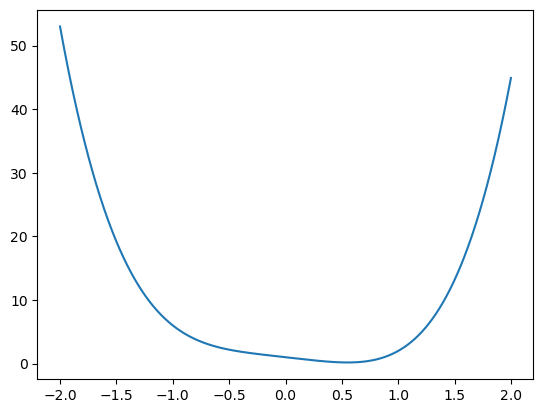

In [2]:
#Optimizing a function of one variable
def g(x):
    return 3*x**4 - 2*x + 1
x=np.arange(-2,2,0.001)
plt.plot(x,g(x))

In [3]:
#Use minimize_scalar to find the minimizer and the minimum.
#fun is the value of the function at the minimum
#x is the minimizer
res = minimize_scalar(g)
res

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: 0.17451818777634331
       x: 0.5503212087491959
     nit: 12
    nfev: 15

In [4]:
g(0.5503212087491959)

0.17451818777634331

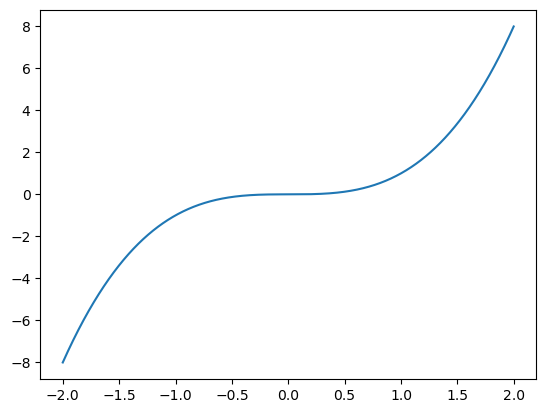

In [5]:
def y(x):
    return x**3

plt.plot(x,y(x))
    

In [6]:
#Sometimes a function does not have a minimum
res1 = minimize_scalar(y)
res1

C:\Users\brusc\anaconda3\Lib\site-packages\scipy\optimize\_optimize.py:2973: RuntimeWarning: overflow encountered in scalar multiply
  w = xb - ((xb - xc) * tmp2 - (xb - xa) * tmp1) / denom
C:\Users\brusc\anaconda3\Lib\site-packages\scipy\optimize\_optimize.py:2966: RuntimeWarning: overflow encountered in scalar multiply
  tmp1 = (xb - xa) * (fb - fc)
C:\Users\brusc\anaconda3\Lib\site-packages\scipy\optimize\_optimize.py:2973: RuntimeWarning: invalid value encountered in scalar divide
  w = xb - ((xb - xc) * tmp2 - (xb - xa) * tmp1) / denom
C:\Users\brusc\anaconda3\Lib\site-packages\scipy\optimize\_optimize.py:2967: RuntimeWarning: overflow encountered in scalar multiply
  tmp2 = (xb - xc) * (fb - fa)
C:\Users\brusc\anaconda3\Lib\site-packages\scipy\optimize\_optimize.py:2968: RuntimeWarning: invalid value encountered in scalar subtract
  val = tmp2 - tmp1
C:\Users\brusc\AppData\Local\Temp\ipykernel_37396\279943474.py:2: RuntimeWarning: overflow encountered in scalar power
  return x**

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -inf
       x: -1.0737622077212198e+103
     nit: 35
    nfev: 528

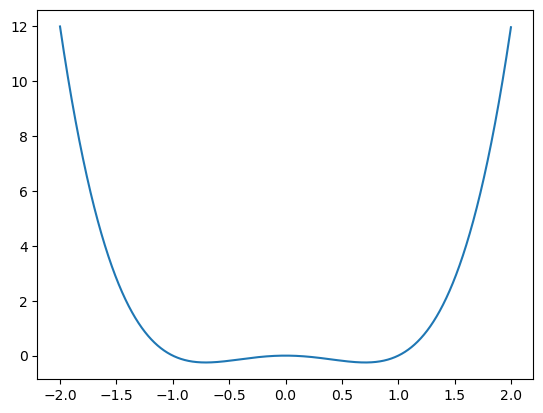

In [7]:
#finding multiple minima
def q(x):
    return x**4 - x**2
plt.plot(x,q(x))


In [8]:
res2=minimize_scalar(q)
res2

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -0.24999999999999994
       x: 0.7071067853059209
     nit: 11
    nfev: 14

In [9]:
1/np.sqrt(2)

0.7071067811865475

In [10]:
#bounds allows you to limit the search in a given interval
res3=minimize_scalar(q,bounds= (0.71,10000))
res3

 message: Solution found.
 success: True
  status: 0
     fun: -0.2499831188070326
       x: 0.710006107647062
     nit: 56
    nfev: 56

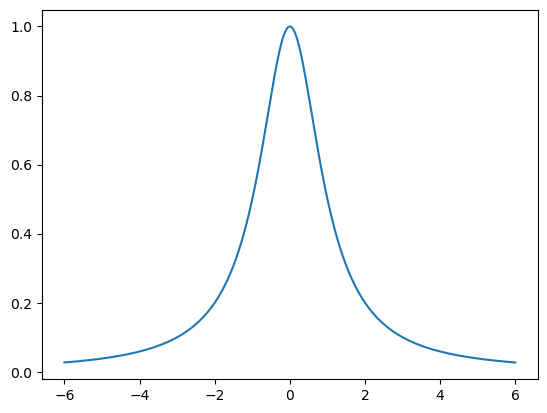

In [11]:
#If we want to look for a maximum, we minimize -f(x)
def h(x):
    return 1/(1+x**2)
z=np.arange(-6,6,0.001)
plt.plot(z,h(z))

In [12]:
#This is what happens if we try to minimize h
res4=minimize_scalar(h)
res4

C:\Users\brusc\anaconda3\Lib\site-packages\scipy\optimize\_optimize.py:2997: RuntimeWarning: overflow encountered in scalar multiply
  elif (w - wlim)*(wlim - xc) >= 0.0:
C:\Users\brusc\anaconda3\Lib\site-packages\scipy\optimize\_optimize.py:3001: RuntimeWarning: overflow encountered in scalar multiply
  elif (w - wlim)*(xc - w) > 0.0:
C:\Users\brusc\AppData\Local\Temp\ipykernel_37396\3246044408.py:3: RuntimeWarning: overflow encountered in scalar power
  return 1/(1+x**2)


 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: 0.0
       x: 2.9162741114952416e+154
     nit: 35
    nfev: 1058

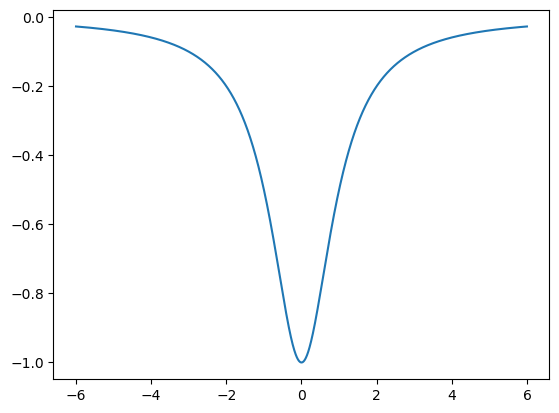

In [13]:
def hh(x):
    return -h(x)
z=np.arange(-6,6,0.001)
plt.plot(z,hh(z))

In [14]:
res5 = minimize_scalar(hh)
res5

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -1.0
       x: -7.656014457860778e-11
     nit: 9
    nfev: 12

In [15]:
#Minimizing a function with many variables
from scipy.optimize import minimize

# 1. Objective Function
def f(x):
    return 2*x[0]**2 - 5*x[0] + 3*x[1]**2

# 2. Initial Guess
initial_guess = [10, 10]

# 3. Solving with SciPy's `minimize`
freemin = minimize(f, initial_guess)
# Output the result
print("Optimal solution:", freemin.x)
print("Objective function value at optimal solution:", freemin.fun)

Optimal solution: [1.25000011e+00 4.26156124e-08]
Objective function value at optimal solution: -3.124999999999971


In [16]:
#Minimizing a function with many variables and one constraints
from scipy.optimize import minimize

# 1. Objective Function
def f(x):
    return 2*x[0]**2 - 5*x[0] + 3*x[1]**2

# 2. Initial Guess
initial_guess = [1, 1]

# 3. Define Constraints. Inequality constraint: x[0] + x[1] <= 1

constraint = {
    'type': 'ineq',  # 'ineq' for inequality
    'fun': lambda x: 1 - (x[0] + x[1])
}
# 4. Solving with SciPy's `minimize`
result_constraints = minimize(f, initial_guess, constraints=[constraint])
# Output the result
print("Optimal solution:", result_constraints.x)
print("Objective function value at optimal solution:", result_constraints.fun)
#The first order conditions are
#4*x[0]-5-lambda=0
#6*x[1]-lambda=0
#lambda*(x[0]+x[1]-1)=0

Optimal solution: [ 1.1 -0.1]
Objective function value at optimal solution: -3.0500000000000003


In [17]:
#Minimizing a function with many variables and one constraint
from scipy.optimize import minimize

# 1. Objective Function
def f(x):
    return 2*x[0]**2 - 5*x[0] + 3*x[1]**2

# 2. Initial Guess
initial_guess = [1, 1]

# 3. Define Constraints. Inequality constraint: x[1] => 0

constraint = {
    'type': 'ineq',  # 'ineq' for inequality
    'fun': lambda x: x[1]
}
# 4. Solving with SciPy's `minimize`
result_constraints = minimize(f, initial_guess, constraints=[constraint])
# Output the result
print("Optimal solution:", result_constraints.x)
print("Objective function value at optimal solution:", result_constraints.fun)
#The first order conditions are
#4*x[0]-5=0
#6*x[1]-lambda=0
#lambda*x[1]=0


Optimal solution: [ 1.25000000e+00 -1.19037124e-15]
Objective function value at optimal solution: -3.1249999999999996


In [18]:
#Minimizing a function with many variables and multiple constraints
# 1. Objective Function
def f(x):
    return 2*x[0]**2 - 5*x[0] + 3*x[1]**2

constraints = [
            {'type': 'ineq', 'fun': lambda x: 1-x[0] - x[1]}, 
        {'type': 'ineq', 'fun': lambda x: 0.75 - x[0]}
        ]

initial_guess = [0, 0]

result = minimize(f, initial_guess, method='SLSQP', constraints=constraints)
result

 message: Optimization terminated successfully
 success: True
  status: 0
     fun: -2.624999999999967
       x: [ 7.500e-01 -4.470e-08]
     nit: 2
     jac: [-2.000e+00 -2.384e-07]
    nfev: 6
    njev: 2

In [19]:
def objective_function(x):
        # x is an array of optimization variables
        return x[0]**2 + x[1]**2 # Example: Minimize x^2 + y^2

constraints = [
            {'type': 'eq', 'fun': lambda x: x[0] + x[1] - 3},  # Equality: x[0] + x[1] = 3
            {'type': 'ineq', 'fun': lambda x: x[0] - x[1] + 1} # Inequality: x[0] - x[1] + 1 >= 0
        ]

initial_guess = [1, 1]

result = minimize(objective_function, initial_guess, method='SLSQP', constraints=constraints)
result

 message: Optimization terminated successfully
 success: True
  status: 0
     fun: 4.5
       x: [ 1.500e+00  1.500e+00]
     nit: 3
     jac: [ 3.000e+00  3.000e+00]
    nfev: 10
    njev: 3

In [20]:
#Portfolio two assets
r0=0.06
r1=0.09
def portreturn(x):
        return -r0*x[0]- r1*x[1]

constraints = [
            {'type': 'ineq', 'fun': lambda x: 1-x[0] },  # Inquality: 1-x[0]  >= 0
            {'type': 'ineq', 'fun': lambda x: 1-x[1]}, # Inequality: 1 - x[1] >= 0            
            {'type': 'ineq', 'fun': lambda x: x[0]}, # Inequality: x[0] >= 0
            {'type': 'ineq', 'fun': lambda x: x[1]}, # Inequality: x[1] >= 0
            {'type': 'ineq', 'fun': lambda x: 1-x[0]-x[1]}, # Inequality: 1-x[0]-x[1] >= 0
        ]

initial_guess = [0.5, 0.5]

result = minimize(portreturn, initial_guess, constraints=constraints)
result

 message: Optimization terminated successfully
 success: True
  status: 0
     fun: -0.09
       x: [-7.078e-16  1.000e+00]
     nit: 5
     jac: [-6.000e-02 -9.000e-02]
    nfev: 15
    njev: 5